# Análisis Exploratorio de VideoGame Radar

Este notebook realiza un análisis exploratorio de los datos de videojuegos descargados de RAWG.

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Carga de datos

In [2]:
conn = sqlite3.connect('../datos.db')

query = """
SELECT 
    j.*,
    GROUP_CONCAT(DISTINCT g.nombre) as generos,
    GROUP_CONCAT(DISTINCT p.nombre) as plataformas
FROM juegos j
LEFT JOIN juego_generos jg ON j.id = jg.juego_id
LEFT JOIN generos g ON jg.genero_id = g.id
LEFT JOIN juego_plataformas jp ON j.id = jp.juego_id
LEFT JOIN plataformas p ON jp.plataforma_id = p.id
GROUP BY j.id
"""

df = pd.read_sql_query(query, conn)
print(f'Total de juegos: {len(df)}')
df.head()

Total de juegos: 1000


,id,slug,nombre,descripcion,fecha_lanzamiento,rating,rating_top,ratings_count,metacritic,playtime,background_image,esrb_rating,updated,generos,plataformas
0,25,middle-earth-shadow-of-war,Middle-earth: Shadow of War,,2017-09-27,3.86,4,1393,82.0,13,https://media.rawg.io/media/games/21a/21ad672c...,Mature,2026-10-09T17:58:53,"Action,RPG","Xbox One,PC,PlayStation 4,Android"
1,27,pyre,Pyre,,2017-07-25,4.16,5,484,84.0,4,https://media.rawg.io/media/games/e63/e635b8c7...,Everyone 10+,2026-08-18T12:47:06,"Adventure,RPG,Arcade,Sports,Indie","PC,macOS,Linux,PlayStation 4"
2,28,red-dead-redemption-2,Red Dead Redemption 2,,2018-10-26,4.59,5,5587,96.0,21,https://media.rawg.io/media/games/511/5118aff5...,Mature,2026-10-23T13:50:15,Action,"Xbox One,PC,PlayStation 4"
3,29,south-park-the-fractured-but-whole,South Park: The Fractured But Whole,,2017-03-31,4.04,4,822,80.0,12,https://media.rawg.io/media/games/63c/63cb0433...,Mature,2026-09-19T19:36:34,"Adventure,RPG","Xbox One,PC,Nintendo Switch,PlayStation 4"
4,32,destiny-2,Destiny 2,,2017-09-06,3.52,4,2674,82.0,6,https://media.rawg.io/media/games/34b/34b1f185...,Teen,2026-09-17T10:42:19,"Shooter,Action","Xbox One,PC,PlayStation 4,Web,Xbox Series S/X,..."


## 2. Información general

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 1000 non-null   int64  
 1   slug               1000 non-null   str    
 2   nombre             1000 non-null   str    
 3   descripcion        1000 non-null   str    
 4   fecha_lanzamiento  1000 non-null   str    
 5   rating             1000 non-null   float64
 6   rating_top         1000 non-null   int64  
 7   ratings_count      1000 non-null   int64  
 8   metacritic         881 non-null    float64
 9   playtime           1000 non-null   int64  
 10  background_image   1000 non-null   str    
 11  esrb_rating        739 non-null    str    
 12  updated            1000 non-null   str    
 13  generos            999 non-null    str    
 14  plataformas        1000 non-null   str    
dtypes: float64(2), int64(4), str(9)
memory usage: 313.0 KB


In [4]:
df.describe()

,id,rating,rating_top,ratings_count,metacritic,playtime
count,1000.000000,1000.000000,1000.000000,1000.000000,881.000000,1000.000000
mean,49598.266000,3.729780,3.997000,940.795000,79.952327,6.637000
std,121676.918118,0.526068,0.735889,850.441497,8.030199,13.164518
min,25.000000,1.820000,1.000000,69.000000,44.000000,0.000000
25%,3846.500000,3.420000,4.000000,390.750000,75.000000,2.000000
50%,11295.500000,3.830000,4.000000,661.500000,81.000000,4.000000
75%,22509.500000,4.130000,4.000000,1183.250000,86.000000,7.000000
max,906547.000000,4.750000,5.000000,7455.000000,97.000000,329.000000


## 3. Distribución de géneros

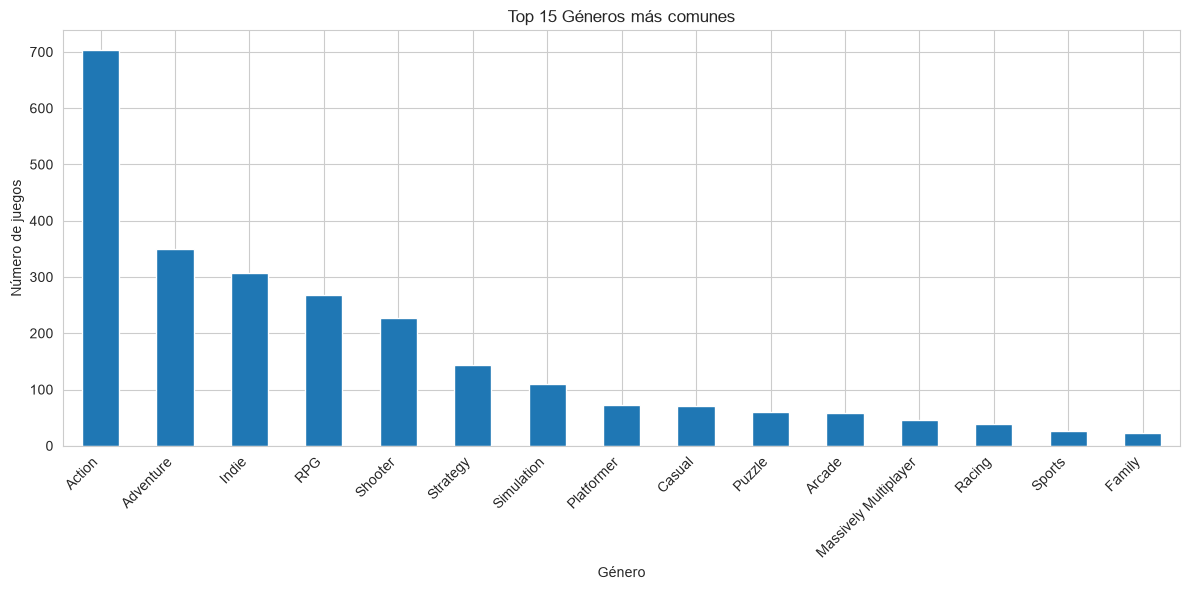

In [5]:
generos_series = df['generos'].str.split(',').explode()
generos_counts = generos_series.value_counts().head(15)

plt.figure(figsize=(12, 6))
generos_counts.plot(kind='bar')
plt.title('Top 15 Géneros más comunes')
plt.xlabel('Género')
plt.ylabel('Número de juegos')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 4. Distribución de plataformas

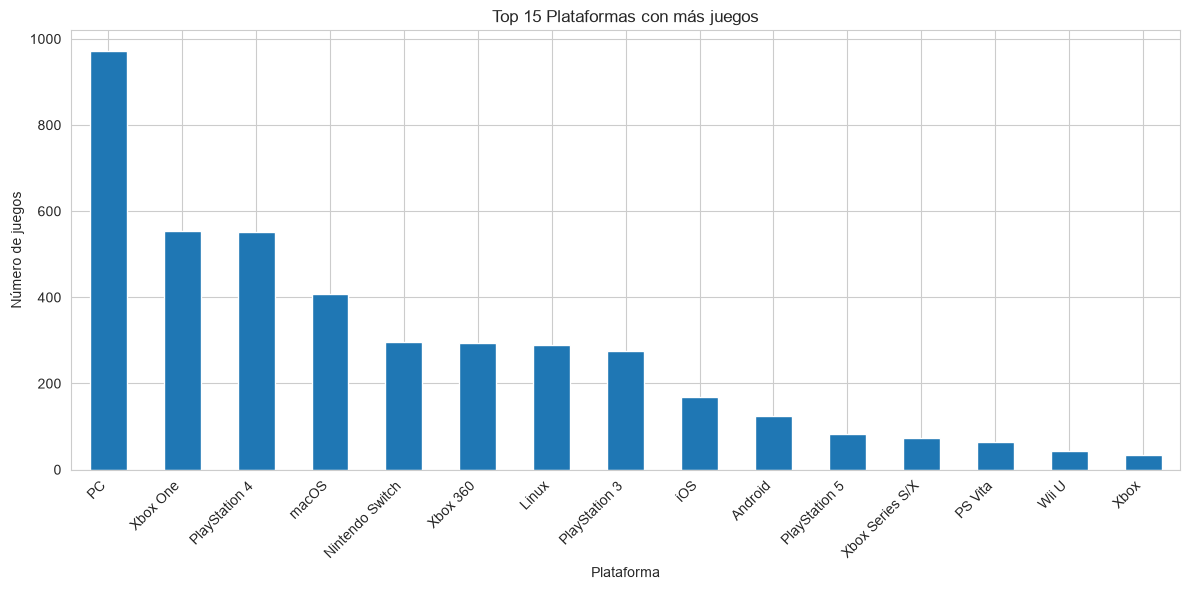

In [6]:
plataformas_series = df['plataformas'].str.split(',').explode()
plataformas_counts = plataformas_series.value_counts().head(15)

plt.figure(figsize=(12, 6))
plataformas_counts.plot(kind='bar')
plt.title('Top 15 Plataformas con más juegos')
plt.xlabel('Plataforma')
plt.ylabel('Número de juegos')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 5. Distribución de ratings

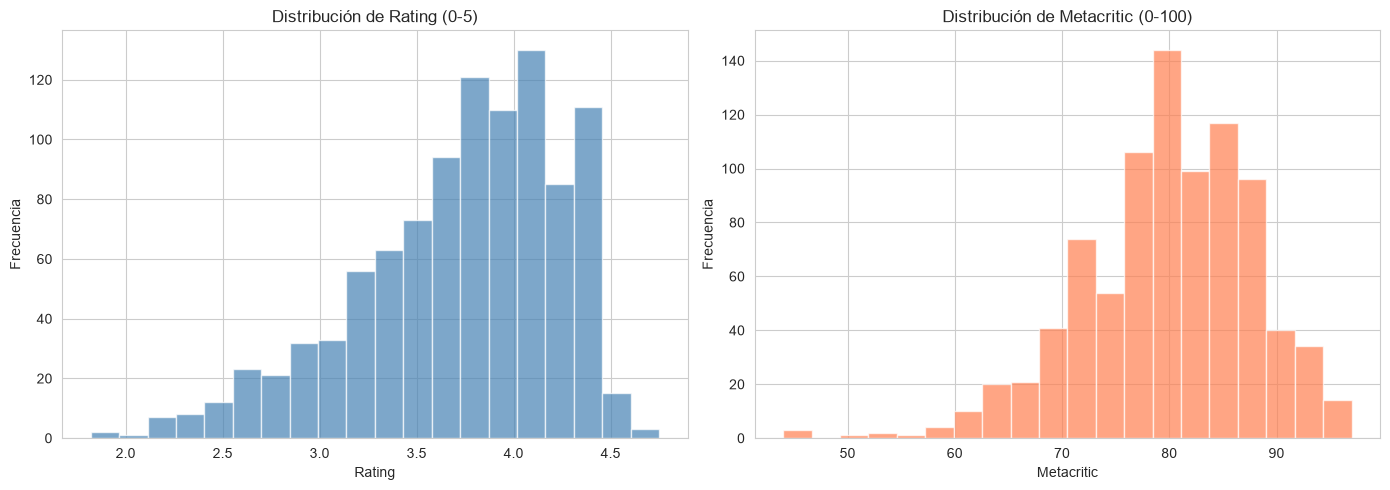

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df['rating'].dropna().hist(bins=20, ax=axes[0], color='steelblue', alpha=0.7)
axes[0].set_title('Distribución de Rating (0-5)')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Frecuencia')

df['metacritic'].dropna().hist(bins=20, ax=axes[1], color='coral', alpha=0.7)
axes[1].set_title('Distribución de Metacritic (0-100)')
axes[1].set_xlabel('Metacritic')
axes[1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

## 6. Top juegos mejor valorados

In [8]:
# Solo juegos con 100 valoraciones o más: con pocos votos el rating no es fiable.
top_juegos = df[df['ratings_count'] >= 100].nlargest(20, 'rating')[['nombre', 'rating', 'ratings_count', 'metacritic', 'generos']]
top_juegos

,nombre,rating,ratings_count,metacritic,generos
945,Persona 5 Royal,4.75,543,94.0,"Adventure,RPG"
229,The Last Of Us Remastered,4.69,2860,95.0,"Adventure,Action"
192,The Witcher 3: Wild Hunt,4.64,7293,92.0,"Action,RPG"
2,Red Dead Redemption 2,4.59,5587,96.0,Action
285,Portal 2,4.57,6149,95.0,"Shooter,Puzzle"
984,Mass Effect: Legendary Edition,4.57,585,88.0,"Shooter,Adventure,Action,RPG"
263,The Last Of Us,4.54,3423,95.0,"Adventure,Action"
868,God of War (2018),4.54,5225,94.0,Action
894,Resident Evil 2,4.51,2312,91.0,"Adventure,Action"
32,Grand Theft Auto: San Andreas,4.50,4120,93.0,Action


## 7. Tendencias de lanzamiento por año

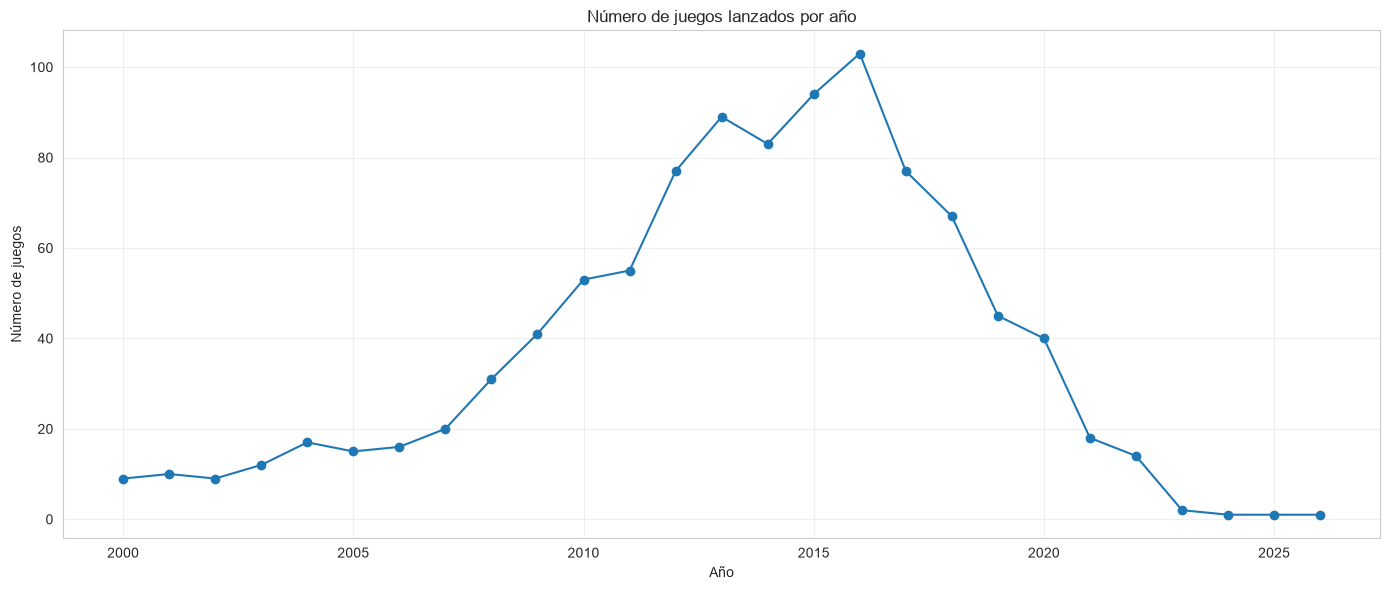

In [9]:
df['fecha_lanzamiento'] = pd.to_datetime(df['fecha_lanzamiento'], errors='coerce')
df['anio'] = df['fecha_lanzamiento'].dt.year

lanzamientos_por_anio = df['anio'].value_counts().sort_index()

plt.figure(figsize=(14, 6))
lanzamientos_por_anio.plot(kind='line', marker='o')
plt.title('Número de juegos lanzados por año')
plt.xlabel('Año')
plt.ylabel('Número de juegos')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 8. Conclusiones

Datos: los 1.000 juegos más populares de RAWG (más añadidos a colecciones de usuarios) lanzados desde el año 2000, descargados en octubre de 2026.

- **Géneros:** Action domina (703 juegos), seguido de Adventure (349), Indie (307) y RPG (268). Un mismo juego suele tener varios géneros.
- **Plataformas:** casi todos están en PC (971); después vienen Xbox One (553) y PlayStation 4 (551).
- **Valoraciones:** el rating medio de usuarios es 3,73 sobre 5 y la nota media de Metacritic, 80 (881 juegos la tienen). Ambas notas van bastante de la mano (correlación de 0,62).
- **Mejor valorados** (con al menos 100 votos): Persona 5 Royal (4,75), The Last of Us Remastered (4,69) y The Witcher 3 (4,64).
- **Años:** el pico está en 2016 (103 juegos) y apenas hay juegos de 2023 en adelante. No es que se publiquen menos: los juegos recientes aún no han acumulado tantos usuarios en RAWG, que es el criterio de popularidad usado.
- **Duración:** la mediana de `playtime` es de 4 horas; es la media declarada por usuarios de RAWG y es poco fiable para juegos largos.
